BEM参考解

=== 多核 BEM 求解无限域受压圆孔问题 ===
孔径 a=1.0m, 外边界 L=80.0m, 内压 P0=1.0e+06Pa, E=1.0e+09Pa, nu=0.3
边界单元数: 外边界=40, 内圆孔=180, 总计=220
组装系统矩阵...
矩阵组装耗时: 1.619 s
求解线性方程组...
提取近场物理场与有限差分应力...
数据提取完成，耗时: 1.231 s


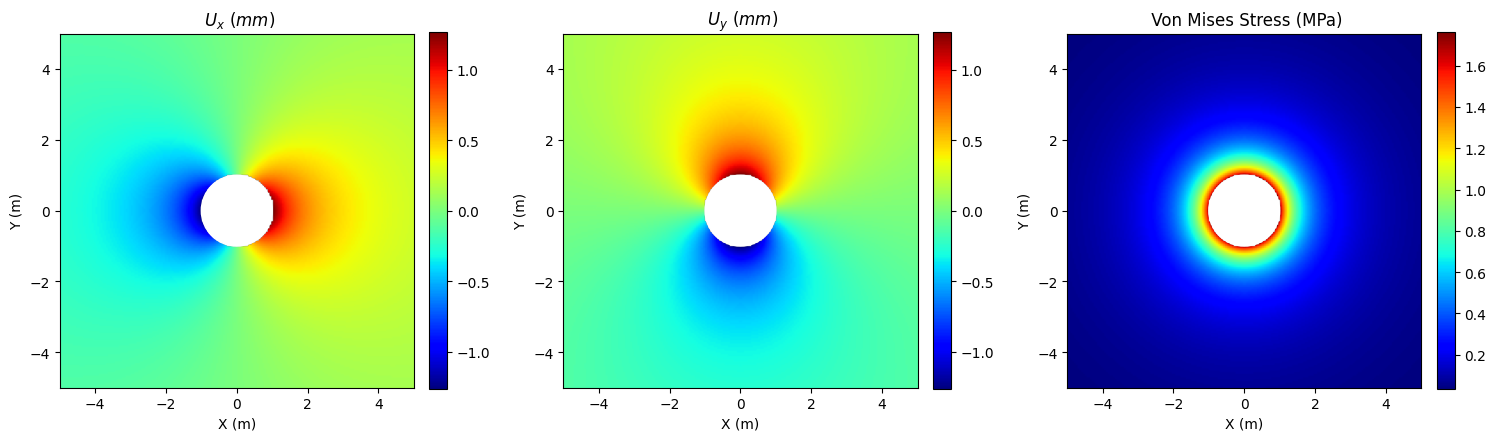

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
import time

# ==========================================
# 1. 物理参数与网格参数 (严格对齐论文截图)
# ==========================================
a = 1.0              # 圆孔半径 (m), 直径为 2a
P0 = 1.0e6           # 圆孔内压 (1 MPa)
E = 1.0e9            # 杨氏模量 (1.0 GPa)
nu = 0.3             # 泊松比

# 论文设定：外边界边长为直径的 40 倍 -> 40 * 2a = 80a
L_out = 80.0 * a     

nu_eff = nu          # 平面应变假设
G_shear = E / (2.0 * (1.0 + nu))

print(f"=== 多核 BEM 求解无限域受压圆孔问题 ===")
print(f"孔径 a={a}m, 外边界 L={L_out}m, 内压 P0={P0:.1e}Pa, E={E:.1e}Pa, nu={nu}")

def analytical_solution(x, y):
    """用于给外边界施加精确位移条件的解析解"""
    r2 = x**2 + y**2
    r = np.sqrt(r2)
    ur = (P0 * a**2) / (2 * G_shear * r)
    ux = ur * (x / r)
    uy = ur * (y / r)
    return ux, uy

# ==========================================
# 2. 生成多连通域边界网格 (外方内圆)
# ==========================================
# 论文设定：内圆孔 180 个单元，外边界 40 个单元(每边10个)
N_hole = 180  
N_side = 10   
N = N_side * 4 + N_hole

nodes = np.zeros((N, 2))
normals = np.zeros((N, 2))
lengths = np.zeros(N)
is_hole = np.zeros(N, dtype=bool)

idx = 0
# 2.1 外边界 (逆时针 CCW，保证计算域在左侧，法向朝外)
coords = np.linspace(-L_out/2, L_out/2, N_side + 1)
for i in range(N_side): # 底边
    nodes[idx] = [(coords[i]+coords[i+1])/2, -L_out/2]; normals[idx] = [0, -1]; lengths[idx] = coords[i+1]-coords[i]; idx += 1
for i in range(N_side): # 右边
    nodes[idx] = [L_out/2, (coords[i]+coords[i+1])/2]; normals[idx] = [1, 0]; lengths[idx] = coords[i+1]-coords[i]; idx += 1
for i in range(N_side): # 顶边 (反向)
    nodes[idx] = [(coords[N_side-i]+coords[N_side-i-1])/2, L_out/2]; normals[idx] = [0, 1]; lengths[idx] = coords[N_side-i]-coords[N_side-i-1]; idx += 1
for i in range(N_side): # 左边 (反向)
    nodes[idx] = [-L_out/2, (coords[N_side-i]+coords[N_side-i-1])/2]; normals[idx] = [-1, 0]; lengths[idx] = coords[N_side-i]-coords[N_side-i-1]; idx += 1

# 2.2 内圆孔 (顺时针 CW，计算域在左侧，法向指向圆心)
theta = np.linspace(0, 2*np.pi, N_hole + 1)
for i in range(N_hole):
    th1 = theta[N_hole - i]      
    th2 = theta[N_hole - i - 1]
    x1, y1 = a * np.cos(th1), a * np.sin(th1)
    x2, y2 = a * np.cos(th2), a * np.sin(th2)
    th_mid = (th1 + th2) / 2
    
    nodes[idx] = [(x1+x2)/2, (y1+y2)/2]
    normals[idx] = [-np.cos(th_mid), -np.sin(th_mid)] # 法向指向圆心
    lengths[idx] = np.sqrt((x2-x1)**2 + (y2-y1)**2)
    is_hole[idx] = True
    idx += 1

# Numba 常数项
C1 = 1.0 / (8.0 * np.pi * G_shear * (1.0 - nu_eff))
C2 = 3.0 - 4.0 * nu_eff
C3 = -1.0 / (4.0 * np.pi * (1.0 - nu_eff))
C4 = 1.0 - 2.0 * nu_eff
gauss_xi, gauss_w = np.polynomial.legendre.leggauss(4)

print(f"边界单元数: 外边界={N_side*4}, 内圆孔={N_hole}, 总计={N}")

# ==========================================
# 3. Numba 核心积分引擎
# ==========================================
@njit(parallel=True)
def assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4):
    N = nodes.shape[0]
    H = np.zeros((2*N, 2*N))
    G = np.zeros((2*N, 2*N))
    n_gauss = len(gauss_xi)
    
    for i in prange(N):
        x_source = nodes[i]
        for j in range(N):
            L_j = lengths[j]
            nx, ny = normals[j, 0], normals[j, 1]
            tx, ty = -ny, nx
            r0, r1 = 2*i, 2*i+1
            c0, c1 = 2*j, 2*j+1
            
            if i == j:
                H[r0, c0] = 0.5; H[r0, c1] = 0.0
                H[r1, c0] = 0.0; H[r1, c1] = 0.5
                g00 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)) + 1.0)
                g11 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)))
                G[r0, c0] = tx*(g00*tx) + nx*(g11*nx); G[r0, c1] = tx*(g00*ty) + nx*(g11*ny)
                G[r1, c0] = ty*(g00*tx) + ny*(g11*nx); G[r1, c1] = ty*(g00*ty) + ny*(g11*ny)
            else:
                y_center = nodes[j]
                H00 = H01 = H10 = H11 = 0.0
                G00 = G01 = G10 = G11 = 0.0
                for g in range(n_gauss):
                    y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                    y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                    rx = y_gpx - x_source[0]; ry = y_gpy - x_source[1]
                    r = np.sqrt(rx*rx + ry*ry)
                    rdx = rx/r; rdy = ry/r
                    dr_dn = rdx*nx + rdy*ny
                    log_1_r = np.log(1.0/r)
                    hw = 0.5 * L_j * gauss_w[g]
                    
                    G00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                    G01 += C1 * (rdx*rdy) * hw
                    G10 += C1 * (rdx*rdy) * hw
                    G11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                    
                    H00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                    H01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                    H10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                    H11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                    
                H[r0, c0] = H00; H[r0, c1] = H01; H[r1, c0] = H10; H[r1, c1] = H11
                G[r0, c0] = G00; G[r0, c1] = G01; G[r1, c0] = G10; G[r1, c1] = G11
    return H, G

t0 = time.time()
print("组装系统矩阵...")
H, G = assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4)
print(f"矩阵组装耗时: {time.time()-t0:.3f} s")

# ==========================================
# 4. 施加边界条件并求解
# ==========================================
A = np.zeros((2*N, 2*N))
B = np.zeros(2*N)
u_known = np.zeros(2*N, dtype=bool); u_val = np.zeros(2*N)
t_known = np.zeros(2*N, dtype=bool); t_val = np.zeros(2*N)

for i in range(N):
    dof_x, dof_y = 2*i, 2*i+1
    if is_hole[i]:
        # 圆孔边界受均匀内压 P0，法向指向圆心
        t_known[dof_x] = True; t_val[dof_x] = -P0 * normals[i, 0]
        t_known[dof_y] = True; t_val[dof_y] = -P0 * normals[i, 1]
    else:
        # 外边界施加位移解析解以模拟无限大平面
        ux_ana, uy_ana = analytical_solution(nodes[i,0], nodes[i,1])
        u_known[dof_x] = True; u_val[dof_x] = ux_ana
        u_known[dof_y] = True; u_val[dof_y] = uy_ana

for k in range(2*N):
    if u_known[k]:
        A[:, k] = -G[:, k]; B -= H[:, k] * u_val[k]
    else:
        A[:, k] = H[:, k]; B += G[:, k] * t_val[k]

print("求解线性方程组...")
X = np.linalg.solve(A, B)

u_bnd = np.where(u_known, u_val, X)
t_bnd = np.where(u_known, X, t_val)

# ==========================================
# 5. 提取观测区域内场数据 (-5 到 5)
# ==========================================
@njit(parallel=True)
def calc_internal_u_numba(pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd):
    N_pts, N = pts.shape[0], nodes.shape[0]
    n_gauss = len(gauss_xi)
    u_out = np.zeros((N_pts, 2))
    
    for q in prange(N_pts):
        xi_x, xi_y = pts[q, 0], pts[q, 1]
        u_x = u_y = 0.0
        for j in range(N):
            y_center = nodes[j]; L_j = lengths[j]
            nx, ny = normals[j, 0], normals[j, 1]; tx, ty = -ny, nx
            U00=U01=U10=U11=T00=T01=T10=T11=0.0
            
            for g in range(n_gauss):
                y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                rx = y_gpx - xi_x; ry = y_gpy - xi_y
                r = np.sqrt(rx*rx + ry*ry)
                rdx = rx/r; rdy = ry/r
                dr_dn = rdx*nx + rdy*ny; log_1_r = np.log(1.0/r)
                hw = 0.5 * L_j * gauss_w[g]
                
                U00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                U01 += C1 * (rdx*rdy) * hw; U10 += C1 * (rdx*rdy) * hw
                U11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                
                T00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                T01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                T10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                T11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                
            uj_x, uj_y = u_bnd[2*j], u_bnd[2*j+1]
            tj_x, tj_y = t_bnd[2*j], t_bnd[2*j+1]
            u_x += (U00*tj_x + U01*tj_y) - (T00*uj_x + T01*uj_y)
            u_y += (U10*tj_x + U11*tj_y) - (T10*uj_x + T11*uj_y)
            
        u_out[q, 0] = u_x
        u_out[q, 1] = u_y
    return u_out

print("提取近场物理场与有限差分应力...")
# 观测区域：修改为 [-5, 5]
L_plot = 5.0 * a
grid_size = 200 # 为保证图片分辨率平滑，网格稍微加密到200x200
coords_1d = np.linspace(-L_plot, L_plot, grid_size)
XX, YY = np.meshgrid(coords_1d, coords_1d)
internal_pts_raw = np.c_[XX.ravel(), YY.ravel()]

# 核心逻辑：只计算圆孔外部的点，内部填 NaN
r_pts = np.sqrt(internal_pts_raw[:,0]**2 + internal_pts_raw[:,1]**2)
valid_mask = (r_pts > a * 1.02) # 为了避免边界奇异性，往外退一点点
internal_pts = internal_pts_raw[valid_mask]

t2 = time.time()
u_int = calc_internal_u_numba(internal_pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

# 中心差分求应变与应力
eps = 1e-4
u_px = calc_internal_u_numba(internal_pts + np.array([eps, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_mx = calc_internal_u_numba(internal_pts - np.array([eps, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_py = calc_internal_u_numba(internal_pts + np.array([0.0, eps]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_my = calc_internal_u_numba(internal_pts - np.array([0.0, eps]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

du_dx = (u_px - u_mx) / (2*eps); du_dy = (u_py - u_my) / (2*eps)
eps_xx = du_dx[:, 0]; eps_yy = du_dy[:, 1]; eps_xy = 0.5 * (du_dx[:, 1] + du_dy[:, 0])

lam = E * nu / ((1 + nu) * (1 - 2 * nu))
mu_lame = E / (2 * (1 + nu))

sig_xx = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_xx
sig_yy = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_yy
sig_xy = 2 * mu_lame * eps_xy
sig_zz = nu * (sig_xx + sig_yy)

von_mises = np.sqrt(0.5 * ((sig_xx - sig_yy)**2 + (sig_yy - sig_zz)**2 + (sig_zz - sig_xx)**2) + 3 * sig_xy**2)

# 将有效数据映射回全网格
U_X_map = np.full(grid_size*grid_size, np.nan)
U_X_map[valid_mask] = u_int[:, 0]

U_Y_map = np.full(grid_size*grid_size, np.nan)
U_Y_map[valid_mask] = u_int[:, 1]

VM_map = np.full(grid_size*grid_size, np.nan)
VM_map[valid_mask] = von_mises

print(f"数据提取完成，耗时: {time.time()-t2:.3f} s")

# ==========================================
# 6. 绘图出图 (Ux, Uy 单位改为 mm, Von Mises 为 MPa)
# ==========================================
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(18, 5))
gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.3)
extent = [-L_plot, L_plot, -L_plot, L_plot]

# 子图 1: Ux 方向位移 (单位: mm)
ax0 = fig.add_subplot(gs[0, 0])
# 1e3 将 m 转换为 mm
im0 = ax0.imshow(U_X_map.reshape(grid_size, grid_size)*1e3, origin='lower', extent=extent, cmap='jet')
ax0.set_xlabel('X (m)'); ax0.set_ylabel('Y (m)')
fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)
ax0.set_title(' $U_x$ ($mm$)')
ax0.add_patch(plt.Circle((0, 0), a, color='white', fill=True)) # 遮盖孔洞

# 子图 2: Uy 方向位移 (单位: mm)
ax1 = fig.add_subplot(gs[0, 1])
# 1e3 将 m 转换为 mm
im1 = ax1.imshow(U_Y_map.reshape(grid_size, grid_size)*1e3, origin='lower', extent=extent, cmap='jet')
ax1.set_xlabel('X (m)'); ax1.set_ylabel('Y (m)')
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
ax1.set_title(' $U_y$ ($mm$)')
ax1.add_patch(plt.Circle((0, 0), a, color='white', fill=True))

# 子图 3: Von Mises 应力 (单位: MPa)
ax2 = fig.add_subplot(gs[0, 2])
# 1e-6 将 Pa 转换为 MPa
im2 = ax2.imshow(VM_map.reshape(grid_size, grid_size)/1e6, origin='lower', extent=extent, cmap='jet')
ax2.set_xlabel('X (m)'); ax2.set_ylabel('Y (m)')
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
ax2.set_title(' Von Mises Stress (MPa)')
ax2.add_patch(plt.Circle((0, 0), a, color='white', fill=True))

plt.show()

## Adaptive neural-network-enhanced KM fundamental-solution method

This version separates the two roles of the solver. The KM point-force kernels form a deterministic physics layer and their spatial derivatives are evaluated analytically. Two small shared neural networks learn smooth normal-offset fields for the hole-interior and outer fictitious-source manifolds. The point-force coefficients retain their linear structure: a fixed-source least-squares solution is used for initialization, followed by adaptive source training and a final linear refit at the learned source locations. The notebook reports fixed/adaptive errors, source movement, conditioning estimates, parameter counts, and source-distribution plots for use in an ablation study.




=== Adaptive neural-network-enhanced KM fundamental-solution solver ===
E*=1000.0, P0*=1.0, G*=384.615385, dtype=torch.float64
Fast demo mode: False
  LS assembly: rows=2000, unknowns=328

--- Fixed-source MFS/KM baseline ---
{'rank': 326, 'boundary_rms': 4.494688854049547e-09, 'boundary_max': 1.0901143987496198e-08, 'condition_est': 4.891386345657392e+17, 'solve_time_s': 0.8551857471466064}
Analytical relative L2 errors: {'ux': 1.0506191159095065e-11, 'uy': 1.0541266092336082e-11, 'sxx': 9.077010913319229e-10, 'syy': 9.077010900343966e-10, 'sxy': 9.061648213258846e-10}
Initial sources: hole radius=[0.7000, 0.7000], std=0.000e+00; outer offset=[8.0000, 8.0000], std=0.000e+00
Coefficient warm-up    0 | loss=1.1223e-16
Coefficient warm-up  100 | loss=3.4945e-08
Coefficient warm-up  200 | loss=6.8102e-10
Coefficient warm-up  299 | loss=2.2293e-10
Adaptive Adam    0 | total=2.2093e-10 | hole=1.909e-11 | outer=2.018e-10 | reg=0.000e+00
Adaptive Adam  150 | total=3.9407e-09 | hole=2.709e-10 

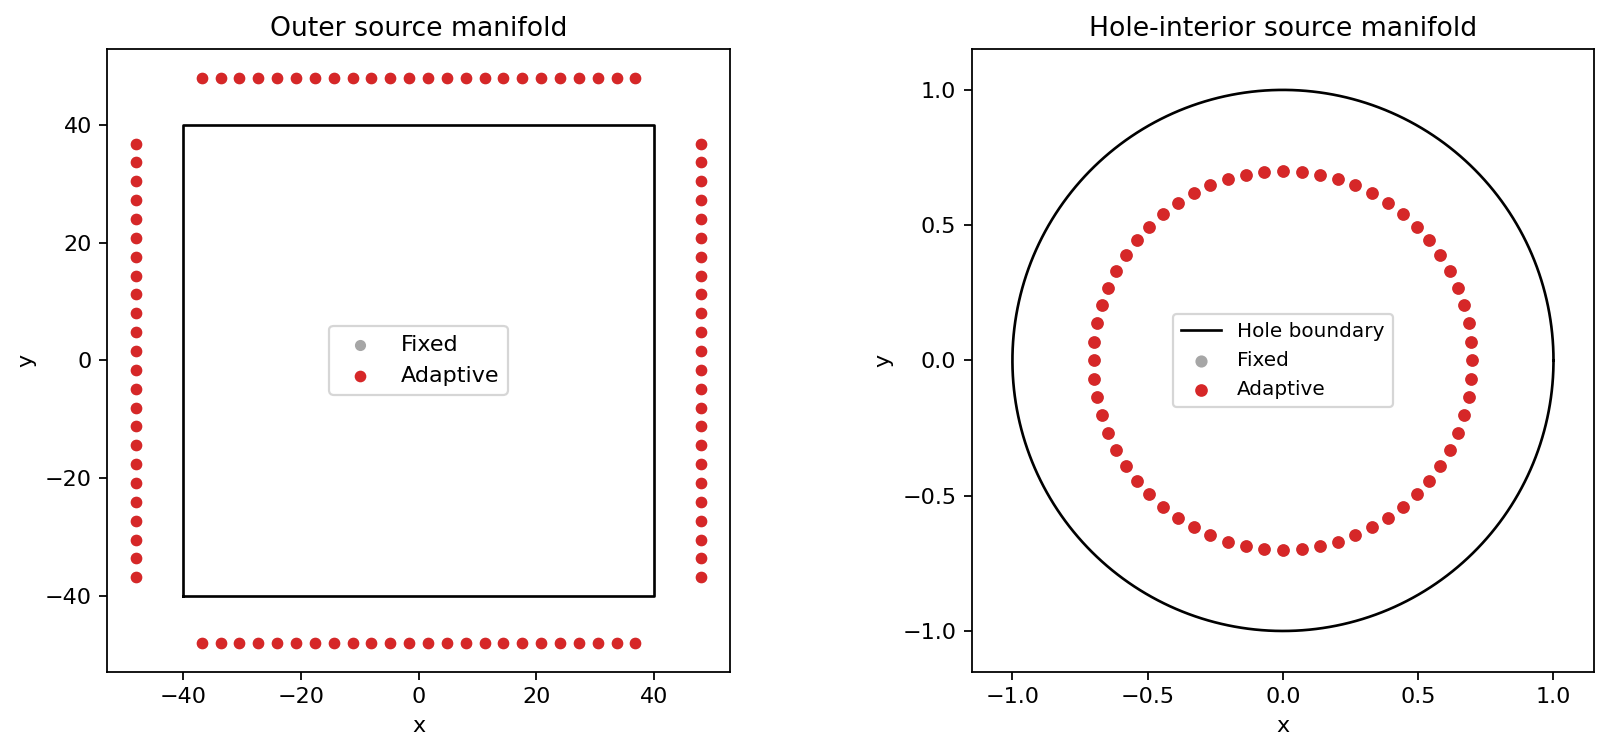

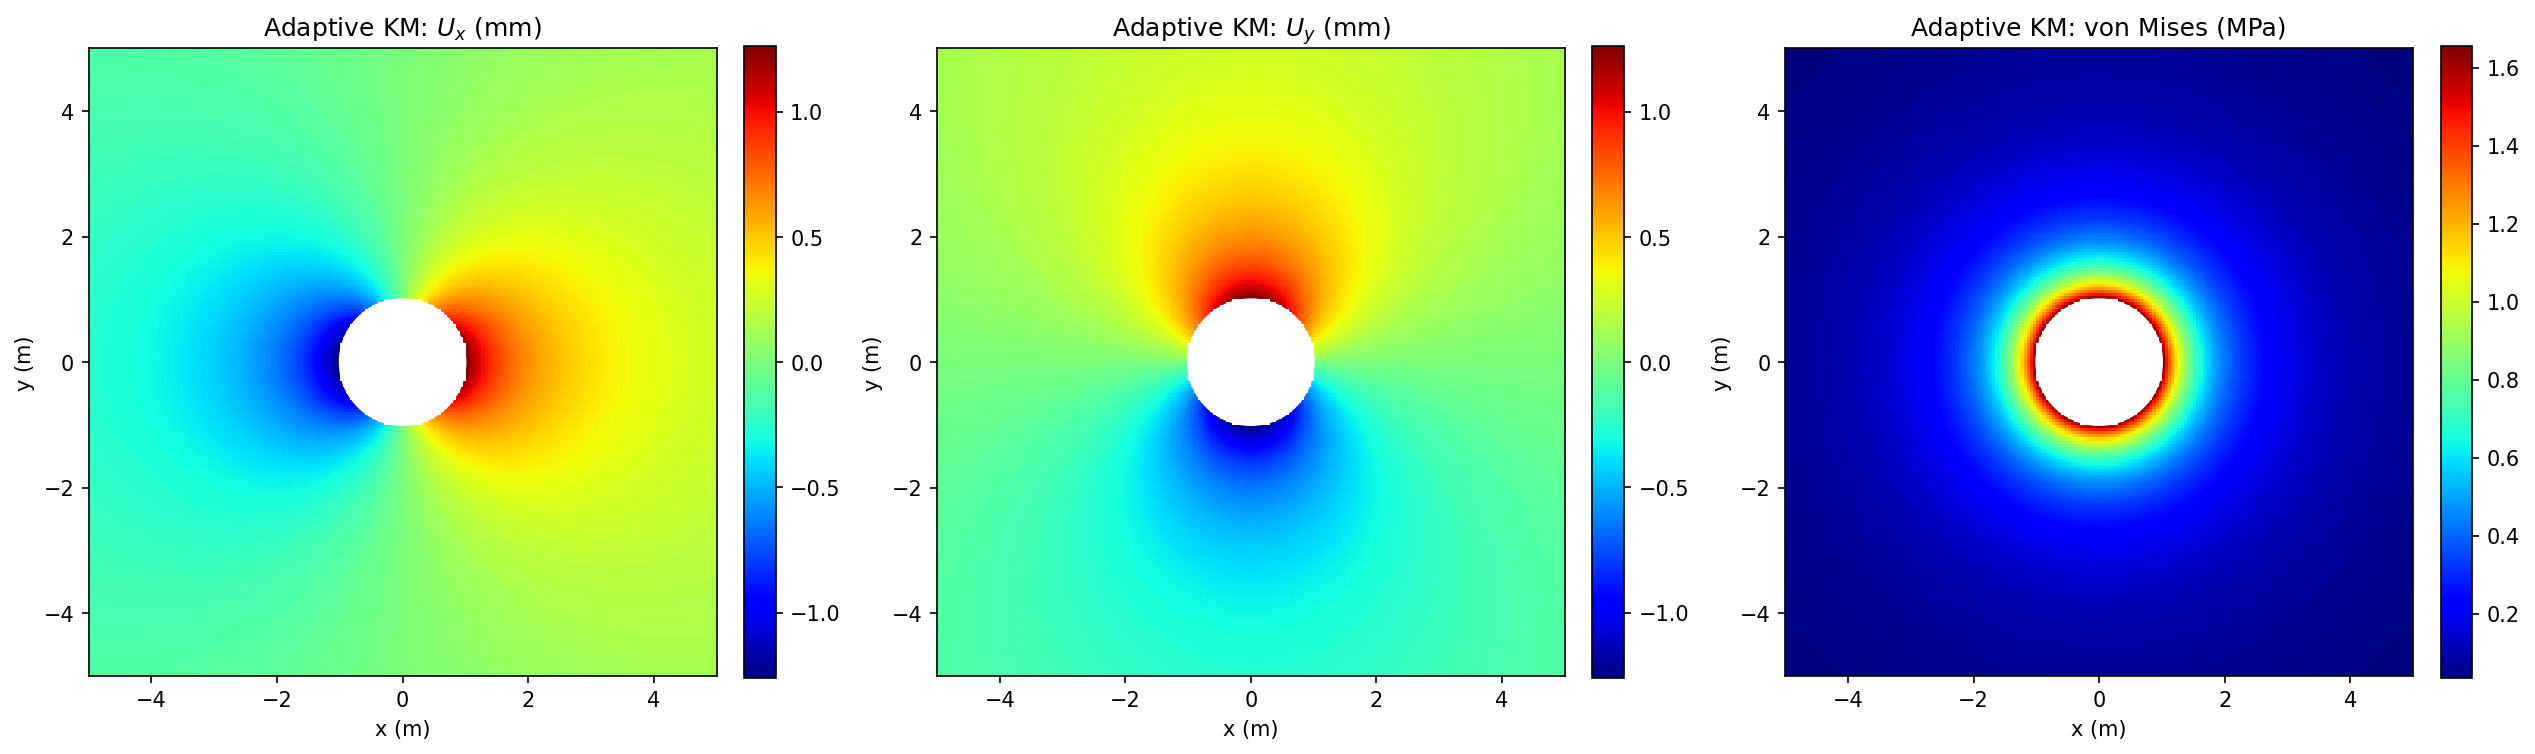

In [ ]:
import os
import time
import random

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn


os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(42)


# ============================================================
# 1. Physical parameters and numerical configuration
# ============================================================

DTYPE = torch.float64
DEVICE = torch.device("cpu")

a = 1.0
P0_real = 1.0e6
E_real = 1.0e9
nu = 0.3
L_out = 80.0 * a

stress_scale = 1.0e6
P0 = P0_real / stress_scale
E = E_real / stress_scale
kappa = 3.0 - 4.0 * nu
G = E / (2.0 * (1.0 + nu))

N_HOLE_SOURCES = 64
N_OUTER_SOURCES_PER_SIDE = 24
N_HOLE_BND = 360
N_OUT_BND = 160

BASE_HOLE_RADIUS = 0.70 * a
BASE_OUTER_OFFSET = 0.10 * L_out

# The source networks only modify the normal distance. Bounded tanh outputs
# guarantee that every singularity remains outside the physical domain.
MAX_HOLE_RADIUS_CHANGE = 0.18 * a
MAX_OUTER_OFFSET_CHANGE = 0.05 * L_out

SOURCE_MOVE_WEIGHT = 2.0e-5
SOURCE_SMOOTH_WEIGHT = 2.0e-4

# Set KM_FAST_DEMO=1 in the environment for a short smoke test.
FAST_DEMO = os.environ.get("KM_FAST_DEMO", "0") == "1"
N_COEFF_WARMUP = 5 if FAST_DEMO else 300
N_ADAPTIVE_ADAM = 10 if FAST_DEMO else 1500
N_LBFGS = 5 if FAST_DEMO else 600

print("=== Adaptive neural-network-enhanced KM fundamental-solution solver ===")
print(f"E*={E:.1f}, P0*={P0:.1f}, G*={G:.6f}, dtype={DTYPE}")
print(f"Fast demo mode: {FAST_DEMO}")


# ============================================================
# 2. Reference source manifolds
# ============================================================

def build_reference_source_data(
    n_hole_sources=N_HOLE_SOURCES,
    n_sources_per_side=N_OUTER_SOURCES_PER_SIDE,
):
    """Reference points and geometric features for the two source manifolds.

    Hole sources move radially inside the excluded circular hole. Outer sources
    move along the outward normal of the artificial square boundary. Their
    tangential ordering is fixed, which prevents source crossing and collapse.
    """
    theta = torch.linspace(
        0.0, 2.0 * np.pi, int(n_hole_sources) + 1,
        dtype=DTYPE, device=DEVICE,
    )[:-1]
    hole_unit = torch.stack((torch.cos(theta), torch.sin(theta)), dim=1)

    # For the symmetric pressurized-hole benchmark, cos(4 theta) and
    # cos(8 theta) impose the expected D4 symmetry of the square truncation.
    hole_features = torch.stack(
        (torch.cos(4.0 * theta), torch.cos(8.0 * theta)), dim=1
    )

    local = torch.linspace(
        -1.0, 1.0, int(n_sources_per_side) + 2,
        dtype=DTYPE, device=DEVICE,
    )[1:-1]
    half = 0.5 * L_out

    bottom_xy = torch.stack((half * local, -half * torch.ones_like(local)), dim=1)
    right_xy = torch.stack((half * torch.ones_like(local), half * local), dim=1)
    top_xy = torch.stack((-half * local, half * torch.ones_like(local)), dim=1)
    left_xy = torch.stack((-half * torch.ones_like(local), -half * local), dim=1)
    outer_boundary_xy = torch.cat((bottom_xy, right_xy, top_xy, left_xy), dim=0)

    normals = torch.tensor(
        [[0.0, -1.0], [1.0, 0.0], [0.0, 1.0], [-1.0, 0.0]],
        dtype=DTYPE, device=DEVICE,
    )
    outer_normals = torch.repeat_interleave(normals, int(n_sources_per_side), dim=0)

    # The same network is shared by all four sides. Even powers of the local
    # coordinate enforce mirror symmetry about every side midpoint.
    local_all = local.repeat(4)
    outer_features = torch.stack((local_all.square(), local_all.pow(4)), dim=1)

    return {
        "theta": theta,
        "hole_unit": hole_unit,
        "hole_features": hole_features,
        "outer_boundary_xy": outer_boundary_xy,
        "outer_normals": outer_normals,
        "outer_features": outer_features,
    }


class SourceOffsetNet(nn.Module):
    """Small shared MLP representing a smooth source-offset field."""

    def __init__(self, in_features=2, hidden=12):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, 1),
        )
        self.net.to(dtype=DTYPE, device=DEVICE)
        # Start exactly from the conventional fixed-source configuration.
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, features):
        return self.net(features).squeeze(-1)


# ============================================================
# 3. Adaptive KM fundamental-solution model
# ============================================================

class AdaptiveKMPIKFNN(nn.Module):
    """KM physics layer plus neural source-manifold parameterization.

    The point-force strengths remain linear trainable kernel coefficients. The
    nonlinear neural-network part learns smooth, geometry-compatible source
    offsets. Thus the network learns the approximation space rather than the
    displacement field or the governing PDE.
    """

    def __init__(
        self,
        n_hole_sources=N_HOLE_SOURCES,
        n_sources_per_side=N_OUTER_SOURCES_PER_SIDE,
        adaptive_sources=True,
    ):
        super().__init__()
        data = build_reference_source_data(n_hole_sources, n_sources_per_side)
        for name, value in data.items():
            self.register_buffer(name, value)

        self.n_hole_sources = int(n_hole_sources)
        self.n_sources_per_side = int(n_sources_per_side)
        self.n_outer_sources = 4 * self.n_sources_per_side
        self.n_basis = self.n_hole_sources + self.n_outer_sources
        self.adaptive_sources = bool(adaptive_sources)

        self.hole_offset_net = SourceOffsetNet(2, 12)
        self.outer_offset_net = SourceOffsetNet(2, 12)

        weight_scale = 1.0e-2 / np.sqrt(self.n_basis)
        self.w_force_re = nn.Parameter(
            weight_scale * torch.randn(self.n_basis, dtype=DTYPE, device=DEVICE)
        )
        self.w_force_im = nn.Parameter(
            weight_scale * torch.randn(self.n_basis, dtype=DTYPE, device=DEVICE)
        )

        # Rows: constant term and coefficient of z. Columns: real and imaginary.
        self.affine_phi = nn.Parameter(torch.zeros(2, 2, dtype=DTYPE, device=DEVICE))
        self.affine_psi = nn.Parameter(torch.zeros(2, 2, dtype=DTYPE, device=DEVICE))

    def source_parameters(self):
        return list(self.hole_offset_net.parameters()) + list(self.outer_offset_net.parameters())

    def kernel_parameters(self):
        source_ids = {id(p) for p in self.source_parameters()}
        return [p for p in self.parameters() if id(p) not in source_ids]

    def source_geometry(self):
        if self.adaptive_sources:
            raw_hole = self.hole_offset_net(self.hole_features)
            raw_outer = self.outer_offset_net(self.outer_features)
        else:
            raw_hole = torch.zeros(self.n_hole_sources, dtype=DTYPE, device=DEVICE)
            raw_outer = torch.zeros(self.n_outer_sources, dtype=DTYPE, device=DEVICE)

        hole_delta = MAX_HOLE_RADIUS_CHANGE * torch.tanh(raw_hole)
        outer_delta = MAX_OUTER_OFFSET_CHANGE * torch.tanh(raw_outer)

        hole_radius = BASE_HOLE_RADIUS + hole_delta
        outer_distance = BASE_OUTER_OFFSET + outer_delta

        hole_xy = hole_radius[:, None] * self.hole_unit
        outer_xy = self.outer_boundary_xy + outer_distance[:, None] * self.outer_normals
        source_xy = torch.cat((hole_xy, outer_xy), dim=0)

        return source_xy, hole_delta, outer_delta, hole_radius, outer_distance

    def source_regularization(self):
        _, hole_delta, outer_delta, _, _ = self.source_geometry()

        move = (
            torch.mean((hole_delta / MAX_HOLE_RADIUS_CHANGE).square())
            + torch.mean((outer_delta / MAX_OUTER_OFFSET_CHANGE).square())
        )

        # Cyclic smoothness for the hole ring.
        hole_smooth = torch.mean((hole_delta - torch.roll(hole_delta, shifts=1)).square())

        # Smoothness along each side of the external square.
        outer_side = outer_delta.reshape(4, self.n_sources_per_side)
        outer_smooth = torch.mean((outer_side[:, 1:] - outer_side[:, :-1]).square())
        smooth = (
            hole_smooth / MAX_HOLE_RADIUS_CHANGE**2
            + outer_smooth / MAX_OUTER_OFFSET_CHANGE**2
        )

        return SOURCE_MOVE_WEIGHT * move + SOURCE_SMOOTH_WEIGHT * smooth

    def source_points_numpy(self):
        with torch.no_grad():
            source_xy = self.source_geometry()[0]
        return source_xy.detach().cpu().numpy()

    @staticmethod
    def _complex_affine(affine, z):
        c = torch.complex(affine[0, 0], affine[0, 1])
        slope = torch.complex(affine[1, 0], affine[1, 1])
        return c + slope * z, slope

    def potentials_and_derivatives(self, x, y):
        """Evaluate Phi, Psi, Phi', Phi'', and Psi' analytically in x,y.

        Spatial derivatives are explicit KM-kernel derivatives. Autograd is only
        used to optimize source-network and kernel parameters.
        """
        x = x.to(dtype=DTYPE, device=DEVICE).reshape(-1)
        y = y.to(dtype=DTYPE, device=DEVICE).reshape(-1)
        z = torch.complex(x, y)

        source_xy = self.source_geometry()[0]
        zeta = torch.complex(source_xy[:, 0], source_xy[:, 1])
        q = z[:, None] - zeta[None, :]

        branch_hole = torch.atan2(source_xy[:self.n_hole_sources, 1], source_xy[:self.n_hole_sources, 0])
        branch_outer = torch.atan2(
            -source_xy[self.n_hole_sources:, 1],
            -source_xy[self.n_hole_sources:, 0],
        )
        branch = torch.cat((branch_hole, branch_outer), dim=0)
        rotated = q * torch.polar(torch.ones_like(branch), -branch)[None, :]

        scale = np.sqrt(self.n_basis)
        log_q = (
            torch.log(torch.clamp(torch.abs(q), min=1.0e-30))
            + 1j * (torch.angle(rotated) + branch[None, :])
        ) / scale
        d1 = (1.0 / q) / scale
        d2 = (-1.0 / q.square()) / scale

        point_force = torch.complex(self.w_force_re, self.w_force_im)
        cf = 1.0 / (2.0 * np.pi * (kappa + 1.0))

        affine_phi, phi_slope = self._complex_affine(self.affine_phi, z)
        affine_psi, psi_slope = self._complex_affine(self.affine_psi, z)

        phi = -cf * (log_q @ point_force) + affine_phi
        dphi = -cf * (d1 @ point_force) + phi_slope
        d2phi = -cf * (d2 @ point_force)

        zeta_bar = torch.conj(zeta)
        psi = cf * (
            kappa * (log_q @ torch.conj(point_force))
            + ((d1 * zeta_bar[None, :]) @ point_force)
        ) + affine_psi
        dpsi = cf * (
            kappa * (d1 @ torch.conj(point_force))
            + ((d2 * zeta_bar[None, :]) @ point_force)
        ) + psi_slope

        return z, phi, psi, dphi, d2phi, dpsi

    def forward(self, x, y):
        _, phi, psi, _, _, _ = self.potentials_and_derivatives(x, y)
        shape = x.shape
        return (
            phi.real.reshape(shape), phi.imag.reshape(shape),
            psi.real.reshape(shape), psi.imag.reshape(shape),
        )


# Compatibility alias for the remaining notebook cells.
CVNN = AdaptiveKMPIKFNN


def get_phys_fields(model, x, y):
    original_shape = x.shape
    z, phi, psi, dphi, d2phi, dpsi = model.potentials_and_derivatives(x, y)

    displacement = (kappa * phi - z * torch.conj(dphi) - torch.conj(psi)) / (2.0 * G)
    sum_sig = 4.0 * dphi.real
    diff_sig = 2.0 * (torch.conj(z) * d2phi + dpsi)

    sig_xx = 0.5 * (sum_sig - diff_sig.real)
    sig_yy = 0.5 * (sum_sig + diff_sig.real)
    sig_xy = 0.5 * diff_sig.imag

    return (
        displacement.real.reshape(original_shape),
        displacement.imag.reshape(original_shape),
        sig_xx.reshape(original_shape),
        sig_yy.reshape(original_shape),
        sig_xy.reshape(original_shape),
    )


# ============================================================
# 4. Boundary-only physics loss
# ============================================================

def _boundary_tensors(n_hole=N_HOLE_BND, n_out=N_OUT_BND):
    theta = torch.linspace(
        0.0, 2.0 * np.pi, int(n_hole) + 1,
        dtype=DTYPE, device=DEVICE,
    )[:-1].reshape(-1, 1)
    x_hole = a * torch.cos(theta)
    y_hole = a * torch.sin(theta)

    coords = torch.linspace(
        -L_out / 2.0, L_out / 2.0, int(n_out) + 2,
        dtype=DTYPE, device=DEVICE,
    )[1:-1].reshape(-1, 1)
    half = torch.full_like(coords, L_out / 2.0)
    outer = {
        "top": (coords.clone(), half.clone()),
        "bottom": (coords.clone(), -half.clone()),
        "right": (half.clone(), coords.clone()),
        "left": (-half.clone(), coords.clone()),
    }
    return x_hole, y_hole, outer


BOUNDARY_DATA = _boundary_tensors()


def get_loss_terms(case_model, n_hole=N_HOLE_BND, n_out=N_OUT_BND):
    if n_hole == N_HOLE_BND and n_out == N_OUT_BND:
        x_hole, y_hole, outer = BOUNDARY_DATA
    else:
        x_hole, y_hole, outer = _boundary_tensors(n_hole, n_out)

    _, _, sig_xx, sig_yy, sig_xy = get_phys_fields(case_model, x_hole, y_hole)
    cos2 = (x_hole.square() - y_hole.square()) / a**2
    sin2 = 2.0 * x_hole * y_hole / a**2
    sig_rr = 0.5 * (sig_xx + sig_yy) + 0.5 * (sig_xx - sig_yy) * cos2 + sig_xy * sin2
    sig_rt = -0.5 * (sig_xx - sig_yy) * sin2 + sig_xy * cos2
    loss_hole = torch.mean((sig_rr + P0).square() + sig_rt.square())

    loss_outer = torch.zeros((), dtype=DTYPE, device=DEVICE)
    for x, y in outer.values():
        ux, uy, _, _, _ = get_phys_fields(case_model, x, y)
        r2 = x.square() + y.square()
        ux_exact = P0 * a**2 * x / (2.0 * G * r2)
        uy_exact = P0 * a**2 * y / (2.0 * G * r2)
        loss_outer = loss_outer + torch.mean(
            ((ux - ux_exact) * (2.0 * G)).square()
            + ((uy - uy_exact) * (2.0 * G)).square()
        )

    source_reg = case_model.source_regularization() if case_model.adaptive_sources else torch.zeros_like(loss_hole)
    total = loss_hole + loss_outer + source_reg
    return {
        "total": total,
        "hole": loss_hole,
        "outer": loss_outer,
        "source_reg": source_reg,
    }


def get_bnd_loss(case_model, n_hole=N_HOLE_BND, n_out=N_OUT_BND):
    return get_loss_terms(case_model, n_hole, n_out)["total"]


# ============================================================
# 5. Linear least-squares solve for fixed/adapted sources
# ============================================================

def build_branch_angles_numpy(source_points, n_hole_sources=N_HOLE_SOURCES):
    source_points = np.asarray(source_points, dtype=float)
    theta = np.empty(len(source_points), dtype=float)
    nh = int(n_hole_sources)
    theta[:nh] = np.arctan2(source_points[:nh, 1], source_points[:nh, 0])
    theta[nh:] = np.arctan2(-source_points[nh:, 1], -source_points[nh:, 0])
    return theta


def _kmfs_coefficient_count(n_basis):
    return 2 * int(n_basis) + 8


def _kmfs_unpack_coeffs(coeffs, n_basis):
    coeffs = np.asarray(coeffs, dtype=float)
    n = int(n_basis)
    point_force = coeffs[:n] + 1j * coeffs[n:2 * n]
    idx = 2 * n
    phi0 = coeffs[idx] + 1j * coeffs[idx + 1]
    phi1 = coeffs[idx + 2] + 1j * coeffs[idx + 3]
    psi0 = coeffs[idx + 4] + 1j * coeffs[idx + 5]
    psi1 = coeffs[idx + 6] + 1j * coeffs[idx + 7]
    return point_force, phi0, phi1, psi0, psi1


def _kmfs_prepare_cache(points, source_points, n_hole_sources=N_HOLE_SOURCES):
    points = np.asarray(points, dtype=float)
    source_points = np.asarray(source_points, dtype=float)
    z = points[:, 0] + 1j * points[:, 1]
    zeta = source_points[:, 0] + 1j * source_points[:, 1]
    q = z[:, None] - zeta[None, :]
    branch = build_branch_angles_numpy(source_points, n_hole_sources)
    rotated = q * np.exp(-1j * branch[None, :])
    scale = np.sqrt(len(zeta))
    log_q = (
        np.log(np.maximum(np.abs(q), 1.0e-300))
        + 1j * (np.angle(rotated) + branch[None, :])
    ) / scale
    return {
        "z": z,
        "log_q": log_q,
        "d1": (1.0 / q) / scale,
        "d2": (-1.0 / q**2) / scale,
        "zeta_bar": np.conj(zeta),
        "n_basis": len(zeta),
    }


def _kmfs_fields_from_coeffs(coeffs, cache):
    z = cache["z"]
    log_q = cache["log_q"]
    d1 = cache["d1"]
    d2 = cache["d2"]
    zeta_bar = cache["zeta_bar"]
    point_force, phi0, phi1, psi0, psi1 = _kmfs_unpack_coeffs(coeffs, cache["n_basis"])
    cf = 1.0 / (2.0 * np.pi * (kappa + 1.0))

    phi = -cf * (log_q @ point_force) + phi0 + phi1 * z
    dphi = -cf * (d1 @ point_force) + phi1
    d2phi = -cf * (d2 @ point_force)
    psi = cf * (
        kappa * (log_q @ np.conj(point_force))
        + (d1 * zeta_bar[None, :]) @ point_force
    ) + psi0 + psi1 * z
    dpsi = cf * (
        kappa * (d1 @ np.conj(point_force))
        + (d2 * zeta_bar[None, :]) @ point_force
    ) + psi1

    disp = (kappa * phi - z * np.conj(dphi) - np.conj(psi)) / (2.0 * G)
    sum_sig = 4.0 * dphi.real
    diff = 2.0 * (np.conj(z) * d2phi + dpsi)
    return disp.real, disp.imag, 0.5 * (sum_sig - diff.real), 0.5 * (sum_sig + diff.real), 0.5 * diff.imag


def _boundary_points_numpy(n_hole=N_HOLE_BND, n_out=N_OUT_BND):
    theta = np.linspace(0.0, 2.0 * np.pi, int(n_hole), endpoint=False)
    hole = np.column_stack((a * np.cos(theta), a * np.sin(theta)))
    t = np.linspace(-L_out / 2.0, L_out / 2.0, int(n_out) + 2)[1:-1]
    half = 0.5 * L_out
    outer = {
        "top": np.column_stack((t, np.full_like(t, half))),
        "bottom": np.column_stack((t, np.full_like(t, -half))),
        "right": np.column_stack((np.full_like(t, half), t)),
        "left": np.column_stack((np.full_like(t, -half), t)),
    }
    return hole, outer


def _kmfs_boundary_residual_numpy(coeffs, caches, points):
    hole, outer = points
    _, _, sxx, syy, sxy = _kmfs_fields_from_coeffs(coeffs, caches["hole"])
    x, y = hole[:, 0], hole[:, 1]
    cos2 = (x**2 - y**2) / a**2
    sin2 = 2.0 * x * y / a**2
    sig_rr = 0.5 * (sxx + syy) + 0.5 * (sxx - syy) * cos2 + sxy * sin2
    sig_rt = -0.5 * (sxx - syy) * sin2 + sxy * cos2
    residuals = [sig_rr + P0, sig_rt]

    for name in ("top", "bottom", "right", "left"):
        ux, uy, _, _, _ = _kmfs_fields_from_coeffs(coeffs, caches[name])
        xy = outer[name]
        r2 = xy[:, 0]**2 + xy[:, 1]**2
        ux_exact = P0 * a**2 * xy[:, 0] / (2.0 * G * r2)
        uy_exact = P0 * a**2 * xy[:, 1] / (2.0 * G * r2)
        residuals.extend(((ux - ux_exact) * (2.0 * G), (uy - uy_exact) * (2.0 * G)))
    return np.concatenate(residuals)


def solve_output_layer_lstsq(source_points, n_hole=N_HOLE_BND, n_out=N_OUT_BND, progress=True):
    t0 = time.time()
    boundary_points = _boundary_points_numpy(n_hole, n_out)
    hole, outer = boundary_points
    caches = {"hole": _kmfs_prepare_cache(hole, source_points)}
    for name, xy in outer.items():
        caches[name] = _kmfs_prepare_cache(xy, source_points)

    n_unknown = _kmfs_coefficient_count(len(source_points))
    zero = np.zeros(n_unknown)
    residual_zero = _kmfs_boundary_residual_numpy(zero, caches, boundary_points)
    matrix = np.empty((residual_zero.size, n_unknown))
    if progress:
        print(f"  LS assembly: rows={matrix.shape[0]}, unknowns={matrix.shape[1]}")
    for column in range(n_unknown):
        unit = np.zeros(n_unknown)
        unit[column] = 1.0
        matrix[:, column] = _kmfs_boundary_residual_numpy(unit, caches, boundary_points) - residual_zero

    coeffs, _, rank, singular_values = np.linalg.lstsq(matrix, -residual_zero, rcond=None)
    residual = matrix @ coeffs + residual_zero
    condition = (
        singular_values[0] / singular_values[-1]
        if singular_values.size and singular_values[-1] > 0.0 else np.inf
    )
    info = {
        "rank": int(rank),
        "boundary_rms": float(np.sqrt(np.mean(residual**2))),
        "boundary_max": float(np.max(np.abs(residual))),
        "condition_est": float(condition),
        "solve_time_s": float(time.time() - t0),
    }
    return coeffs, info


def load_output_coefficients(model, coeffs):
    point_force, phi0, phi1, psi0, psi1 = _kmfs_unpack_coeffs(coeffs, model.n_basis)
    with torch.no_grad():
        model.w_force_re.copy_(torch.as_tensor(point_force.real, dtype=DTYPE, device=DEVICE))
        model.w_force_im.copy_(torch.as_tensor(point_force.imag, dtype=DTYPE, device=DEVICE))
        model.affine_phi.copy_(torch.tensor(
            [[phi0.real, phi0.imag], [phi1.real, phi1.imag]], dtype=DTYPE, device=DEVICE
        ))
        model.affine_psi.copy_(torch.tensor(
            [[psi0.real, psi0.imag], [psi1.real, psi1.imag]], dtype=DTYPE, device=DEVICE
        ))


# Backward-compatible wrapper retained for later notebook use.
def solve_kmfsnet_output_layer_lstsq(
    n_sources_per_side=N_OUTER_SOURCES_PER_SIDE,
    source_offset=BASE_OUTER_OFFSET,
    n_hole_sources=N_HOLE_SOURCES,
    hole_source_scale=BASE_HOLE_RADIUS / a,
    n_hole=N_HOLE_BND,
    n_out=N_OUT_BND,
    rcond=None,
    progress=True,
):
    del source_offset, hole_source_scale, rcond
    temporary = AdaptiveKMPIKFNN(
        n_hole_sources=n_hole_sources,
        n_sources_per_side=n_sources_per_side,
        adaptive_sources=False,
    )
    return solve_output_layer_lstsq(temporary.source_points_numpy(), n_hole, n_out, progress)


load_kmfsnet_coeffs_into_model = load_output_coefficients


# ============================================================
# 6. Diagnostics and visualization
# ============================================================

def source_statistics(model):
    with torch.no_grad():
        _, _, _, hole_radius, outer_distance = model.source_geometry()
    return {
        "hole_radius_min": float(hole_radius.min()),
        "hole_radius_max": float(hole_radius.max()),
        "hole_radius_std": float(hole_radius.std()),
        "outer_distance_min": float(outer_distance.min()),
        "outer_distance_max": float(outer_distance.max()),
        "outer_distance_std": float(outer_distance.std()),
    }


def print_source_statistics(label, model):
    stats = source_statistics(model)
    print(
        f"{label}: hole radius=[{stats['hole_radius_min']:.4f}, "
        f"{stats['hole_radius_max']:.4f}], std={stats['hole_radius_std']:.3e}; "
        f"outer offset=[{stats['outer_distance_min']:.4f}, "
        f"{stats['outer_distance_max']:.4f}], std={stats['outer_distance_std']:.3e}"
    )
    return stats


def plot_source_evolution(initial_points, final_points):
    initial_points = np.asarray(initial_points)
    final_points = np.asarray(final_points)
    nh = N_HOLE_SOURCES
    theta = np.linspace(0.0, 2.0 * np.pi, 500)
    square = np.array([
        [-L_out / 2, -L_out / 2], [L_out / 2, -L_out / 2],
        [L_out / 2, L_out / 2], [-L_out / 2, L_out / 2],
        [-L_out / 2, -L_out / 2],
    ])

    fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.8), dpi=160)
    axes[0].plot(square[:, 0], square[:, 1], "k-", lw=1.2)
    axes[0].scatter(initial_points[nh:, 0], initial_points[nh:, 1], s=16, c="0.65", label="Fixed")
    axes[0].scatter(final_points[nh:, 0], final_points[nh:, 1], s=18, c="#d62728", label="Adaptive")
    axes[0].set_title("Outer source manifold")
    axes[0].set_aspect("equal")
    axes[0].legend()

    axes[1].plot(a * np.cos(theta), a * np.sin(theta), "k-", lw=1.2, label="Hole boundary")
    axes[1].scatter(initial_points[:nh, 0], initial_points[:nh, 1], s=20, c="0.65", label="Fixed")
    axes[1].scatter(final_points[:nh, 0], final_points[:nh, 1], s=22, c="#d62728", label="Adaptive")
    axes[1].set_xlim(-1.15 * a, 1.15 * a)
    axes[1].set_ylim(-1.15 * a, 1.15 * a)
    axes[1].set_title("Hole-interior source manifold")
    axes[1].set_aspect("equal")
    axes[1].legend(fontsize=9)
    for ax in axes:
        ax.set_xlabel("x")
        ax.set_ylabel("y")
    plt.tight_layout()
    plt.show()
    return fig, axes


def relative_l2(prediction, reference):
    return float(np.linalg.norm(prediction - reference) / max(np.linalg.norm(reference), 1.0e-15))


def analytic_errors(case_model, n_r=80, n_theta=180):
    radii = np.geomspace(1.02 * a, 5.0 * a, int(n_r))
    angles = np.linspace(0.0, 2.0 * np.pi, int(n_theta), endpoint=False)
    rr, tt = np.meshgrid(radii, angles, indexing="ij")
    x = (rr * np.cos(tt)).reshape(-1, 1)
    y = (rr * np.sin(tt)).reshape(-1, 1)
    xt = torch.as_tensor(x, dtype=DTYPE, device=DEVICE)
    yt = torch.as_tensor(y, dtype=DTYPE, device=DEVICE)
    with torch.no_grad():
        ux, uy, sxx, syy, sxy = get_phys_fields(case_model, xt, yt)
    ux = ux.cpu().numpy().reshape(-1)
    uy = uy.cpu().numpy().reshape(-1)
    sxx = sxx.cpu().numpy().reshape(-1)
    syy = syy.cpu().numpy().reshape(-1)
    sxy = sxy.cpu().numpy().reshape(-1)

    xf, yf = x.reshape(-1), y.reshape(-1)
    r2 = xf**2 + yf**2
    ux_ref = P0 * a**2 * xf / (2.0 * G * r2)
    uy_ref = P0 * a**2 * yf / (2.0 * G * r2)
    sxx_ref = -P0 * a**2 * (xf**2 - yf**2) / r2**2
    syy_ref = P0 * a**2 * (xf**2 - yf**2) / r2**2
    sxy_ref = -2.0 * P0 * a**2 * xf * yf / r2**2
    return {
        "ux": relative_l2(ux, ux_ref),
        "uy": relative_l2(uy, uy_ref),
        "sxx": relative_l2(sxx, sxx_ref),
        "syy": relative_l2(syy, syy_ref),
        "sxy": relative_l2(sxy, sxy_ref),
    }


# ============================================================
# 7. Fixed-source baseline and adaptive-source training
# ============================================================

if __name__ == "__main__":
    start_time = time.time()

    fixed_model = AdaptiveKMPIKFNN(adaptive_sources=False)
    fixed_source_points = fixed_model.source_points_numpy()
    fixed_coeffs, FIXED_SOURCE_LS_INFO = solve_output_layer_lstsq(fixed_source_points)
    load_output_coefficients(fixed_model, fixed_coeffs)
    FIXED_SOURCE_BOUNDARY_LOSS = float(get_loss_terms(fixed_model)["total"].detach())
    FIXED_SOURCE_ANALYTIC_ERRORS = analytic_errors(fixed_model)
    print("\n--- Fixed-source MFS/KM baseline ---")
    print(FIXED_SOURCE_LS_INFO)
    print("Analytical relative L2 errors:", FIXED_SOURCE_ANALYTIC_ERRORS)

    model = AdaptiveKMPIKFNN(adaptive_sources=True)
    load_output_coefficients(model, fixed_coeffs)
    INITIAL_SOURCE_POINTS = model.source_points_numpy().copy()
    print_source_statistics("Initial sources", model)

    # Stage A: retain the fixed manifold and warm up only linear kernel weights.
    for parameter in model.source_parameters():
        parameter.requires_grad_(False)
    optimizer = torch.optim.Adam(model.kernel_parameters(), lr=4.0e-4)
    for epoch in range(N_COEFF_WARMUP):
        optimizer.zero_grad()
        terms = get_loss_terms(model)
        terms["total"].backward()
        optimizer.step()
        if epoch % max(1, N_COEFF_WARMUP // 3) == 0 or epoch == N_COEFF_WARMUP - 1:
            print(f"Coefficient warm-up {epoch:4d} | loss={terms['total'].item():.4e}")

    # Stage B: jointly learn a smooth source manifold and kernel coefficients.
    for parameter in model.source_parameters():
        parameter.requires_grad_(True)
    optimizer = torch.optim.Adam([
        {"params": model.kernel_parameters(), "lr": 2.5e-4},
        {"params": model.source_parameters(), "lr": 8.0e-4},
    ])

    ADAPTIVE_TRAINING_HISTORY = []
    for epoch in range(N_ADAPTIVE_ADAM):
        optimizer.zero_grad()
        terms = get_loss_terms(model)
        terms["total"].backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=100.0)
        optimizer.step()

        if epoch % max(1, N_ADAPTIVE_ADAM // 10) == 0 or epoch == N_ADAPTIVE_ADAM - 1:
            stats = source_statistics(model)
            ADAPTIVE_TRAINING_HISTORY.append({
                "epoch": epoch,
                "total": float(terms["total"].detach()),
                "hole": float(terms["hole"].detach()),
                "outer": float(terms["outer"].detach()),
                "source_reg": float(terms["source_reg"].detach()),
                **stats,
            })
            print(
                f"Adaptive Adam {epoch:4d} | total={terms['total'].item():.4e} | "
                f"hole={terms['hole'].item():.3e} | outer={terms['outer'].item():.3e} | "
                f"reg={terms['source_reg'].item():.3e}"
            )

    # Exact linear refit at the learned source positions (block variable projection).
    adapted_points_before_lbfgs = model.source_points_numpy()
    adapted_coeffs, ADAPTED_REFIT_INFO = solve_output_layer_lstsq(adapted_points_before_lbfgs)
    load_output_coefficients(model, adapted_coeffs)
    print("\nLinear refit at adapted sources:", ADAPTED_REFIT_INFO)

    # Stage C: a short coupled L-BFGS correction.
    lbfgs = torch.optim.LBFGS(
        model.parameters(), lr=0.5, max_iter=N_LBFGS,
        max_eval=int(1.5 * N_LBFGS) + 1,
        history_size=80, tolerance_grad=1.0e-10,
        tolerance_change=1.0e-12, line_search_fn="strong_wolfe",
    )
    lbfgs_calls = [0]

    def closure():
        lbfgs.zero_grad()
        loss = get_loss_terms(model)["total"]
        loss.backward()
        lbfgs_calls[0] += 1
        return loss

    lbfgs.step(closure)

    # Final exact refit preserves the learned source geometry while exploiting
    # the linear structure of the complex point-force coefficients.
    FINAL_SOURCE_POINTS = model.source_points_numpy()
    final_coeffs, FINAL_ADAPTIVE_LS_INFO = solve_output_layer_lstsq(FINAL_SOURCE_POINTS)
    load_output_coefficients(model, final_coeffs)

    final_terms = get_loss_terms(model)
    final_loss = float(final_terms["total"].detach())
    KM_PIKFNN_TRAIN_TIME = time.time() - start_time
    ADAPTIVE_SOURCE_STATS = print_source_statistics("Final adaptive sources", model)
    ADAPTIVE_SOURCE_ANALYTIC_ERRORS = analytic_errors(model)

    print("\n--- Final fixed/adaptive comparison ---")
    print(f"Fixed-source boundary loss    : {FIXED_SOURCE_BOUNDARY_LOSS:.6e}")
    print(f"Adaptive-source boundary loss : {final_loss:.6e}")
    print(f"Fixed-source cond(A)          : {FIXED_SOURCE_LS_INFO['condition_est']:.6e}")
    print(f"Adaptive-source cond(A)       : {FINAL_ADAPTIVE_LS_INFO['condition_est']:.6e}")
    print("Adaptive analytical relative L2 errors:", ADAPTIVE_SOURCE_ANALYTIC_ERRORS)
    print(f"Total training time: {KM_PIKFNN_TRAIN_TIME:.2f} s")
    print(
        "Trainable parameters: "
        f"kernel={sum(p.numel() for p in model.kernel_parameters())}, "
        f"source networks={sum(p.numel() for p in model.source_parameters())}, "
        f"total={sum(p.numel() for p in model.parameters())}"
    )

    plot_source_evolution(INITIAL_SOURCE_POINTS, FINAL_SOURCE_POINTS)

    # ========================================================
    # 8. Full-field reconstruction on [-5a, 5a]^2
    # ========================================================
    L_plot = 5.0 * a
    grid_size = 200
    coords_1d = np.linspace(-L_plot, L_plot, grid_size)
    XX, YY = np.meshgrid(coords_1d, coords_1d)
    valid_mask = np.sqrt(XX**2 + YY**2) >= 1.02 * a

    X_tensor = torch.as_tensor(XX[valid_mask].reshape(-1, 1), dtype=DTYPE, device=DEVICE)
    Y_tensor = torch.as_tensor(YY[valid_mask].reshape(-1, 1), dtype=DTYPE, device=DEVICE)
    model.eval()
    with torch.no_grad():
        u_x_pred, u_y_pred, sig_xx_pred, sig_yy_pred, sig_xy_pred = get_phys_fields(model, X_tensor, Y_tensor)

    u_x_mm = u_x_pred.cpu().numpy().reshape(-1) * 1.0e3
    u_y_mm = u_y_pred.cpu().numpy().reshape(-1) * 1.0e3
    sig_xx_MPa = sig_xx_pred.cpu().numpy().reshape(-1)
    sig_yy_MPa = sig_yy_pred.cpu().numpy().reshape(-1)
    sig_xy_MPa = sig_xy_pred.cpu().numpy().reshape(-1)
    sig_zz_MPa = nu * (sig_xx_MPa + sig_yy_MPa)
    von_mises_MPa = np.sqrt(
        0.5 * ((sig_xx_MPa - sig_yy_MPa)**2
               + (sig_yy_MPa - sig_zz_MPa)**2
               + (sig_zz_MPa - sig_xx_MPa)**2)
        + 3.0 * sig_xy_MPa**2
    )

    def make_map(values):
        result = np.full((grid_size, grid_size), np.nan)
        result[valid_mask] = values
        return result

    U_X_map = make_map(u_x_mm)
    U_Y_map = make_map(u_y_mm)
    VM_map = make_map(von_mises_MPa)

    fig, axes = plt.subplots(1, 3, figsize=(17, 5), dpi=150)
    extent = [-L_plot, L_plot, -L_plot, L_plot]
    for ax, values, title in zip(
        axes,
        (U_X_map, U_Y_map, VM_map),
        (r"Adaptive KM: $U_x$ (mm)", r"Adaptive KM: $U_y$ (mm)", "Adaptive KM: von Mises (MPa)"),
    ):
        image = ax.imshow(values, origin="lower", extent=extent, cmap="jet")
        ax.add_patch(plt.Circle((0.0, 0.0), a, color="white"))
        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")
        ax.set_title(title)
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

    # Variables retained for the original BEM-comparison and export cells.
    KM_GRID_UX_VALID_M = u_x_pred.cpu().numpy().reshape(-1).copy()
    KM_GRID_UY_VALID_M = u_y_pred.cpu().numpy().reshape(-1).copy()
    KM_GRID_SXX_VALID_PA = sig_xx_pred.cpu().numpy().reshape(-1).copy() * stress_scale
    KM_GRID_SYY_VALID_PA = sig_yy_pred.cpu().numpy().reshape(-1).copy() * stress_scale
    KM_GRID_SXY_VALID_PA = sig_xy_pred.cpu().numpy().reshape(-1).copy() * stress_scale





=== Fixed/adaptive KM fundamental-solution comparison against BEM ===
----------------------------------------------------------------------------
Method                              L2(Ux)        L2(Uy)     L2(von Mises)
Fixed-source KM/MFS             2.7614e-03    2.7614e-03        5.9918e-03
Adaptive-source KM-NN           2.7614e-03    2.7614e-03        5.9918e-03
----------------------------------------------------------------------------


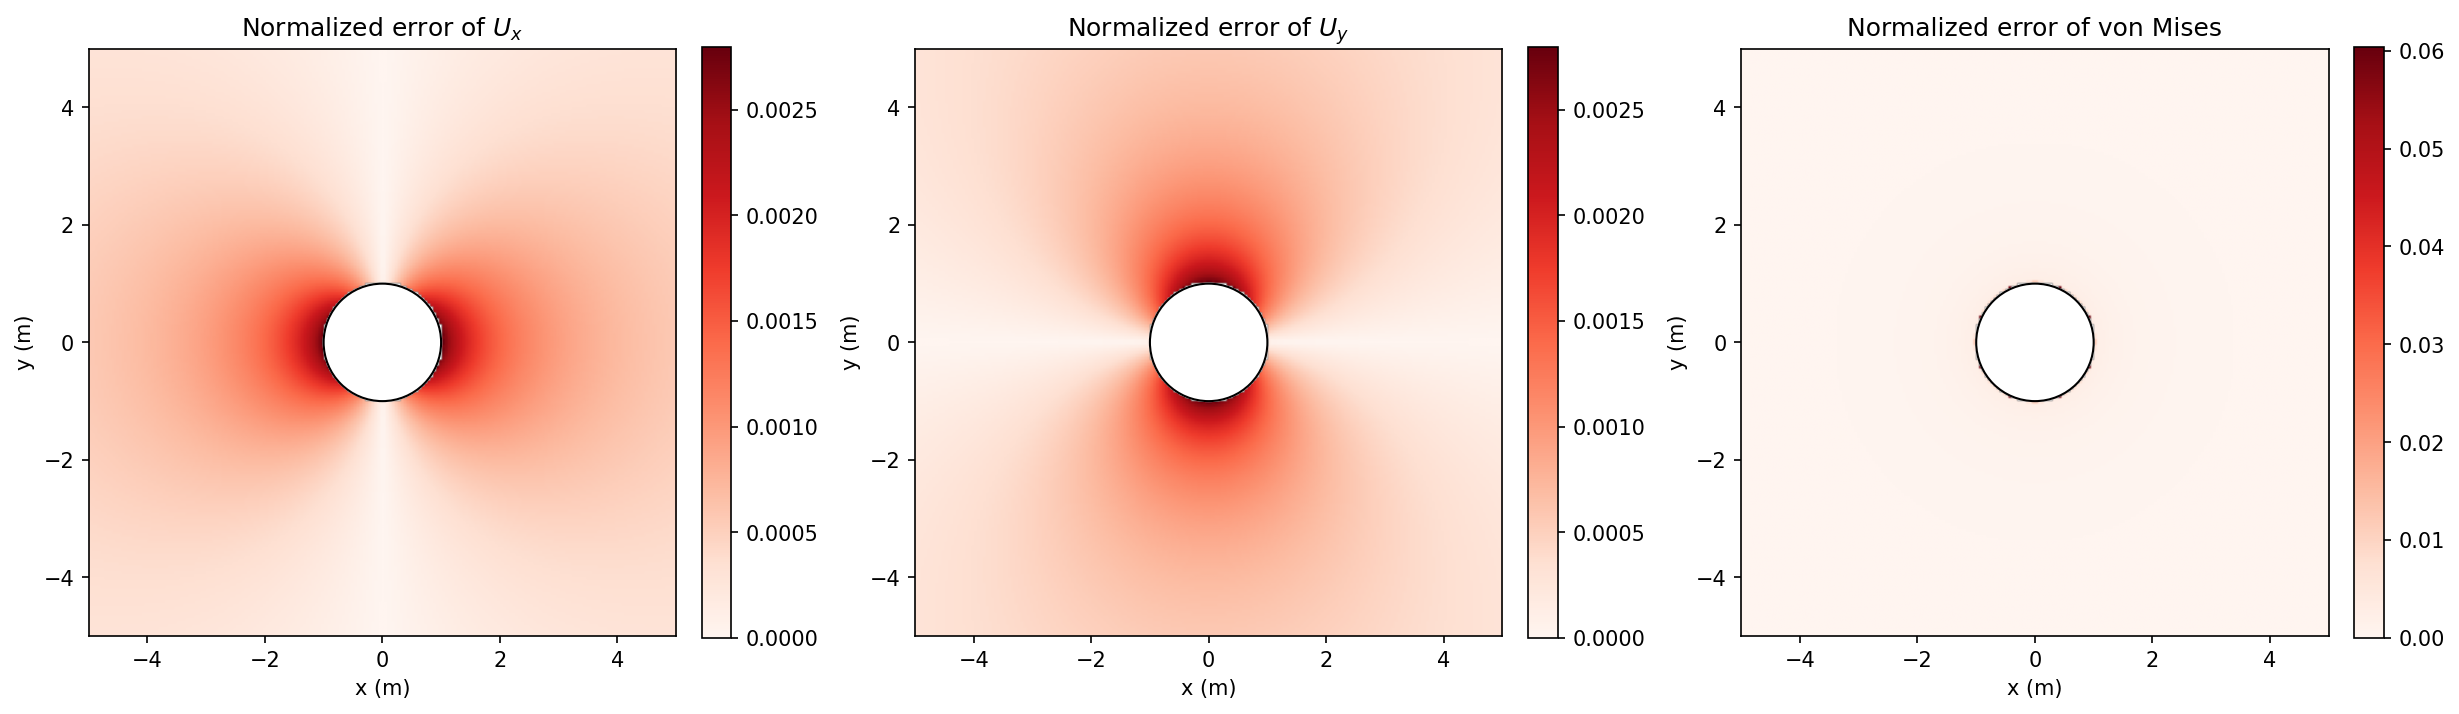

In [ ]:
# ============================================================
# 9. Fixed-source and adaptive-source KM comparison against BEM
# ============================================================

print("\n=== Fixed/adaptive KM fundamental-solution comparison against BEM ===")

required_bem = ["internal_pts", "u_int", "von_mises"]
missing_bem = [name for name in required_bem if name not in globals()]
if missing_bem:
    raise NameError(
        "Run the BEM reference cell first. Missing variables: "
        + ", ".join(missing_bem)
    )


def _evaluate_model_on_bem_points(case_model):
    x_eval = torch.as_tensor(
        internal_pts[:, 0:1], dtype=DTYPE, device=DEVICE
    )
    y_eval = torch.as_tensor(
        internal_pts[:, 1:2], dtype=DTYPE, device=DEVICE
    )
    case_model.eval()
    with torch.no_grad():
        ux, uy, sxx, syy, sxy = get_phys_fields(case_model, x_eval, y_eval)

    ux = ux.cpu().numpy().reshape(-1)
    uy = uy.cpu().numpy().reshape(-1)
    sxx = sxx.cpu().numpy().reshape(-1) * stress_scale
    syy = syy.cpu().numpy().reshape(-1) * stress_scale
    sxy = sxy.cpu().numpy().reshape(-1) * stress_scale
    szz = nu * (sxx + syy)
    vm = np.sqrt(
        0.5 * ((sxx - syy) ** 2 + (syy - szz) ** 2 + (szz - sxx) ** 2)
        + 3.0 * sxy**2
    )
    return ux, uy, vm


u_bem_ref = np.asarray(u_int[:, 0], dtype=float).reshape(-1)
v_bem_ref = np.asarray(u_int[:, 1], dtype=float).reshape(-1)
vm_bem_ref = np.asarray(von_mises, dtype=float).reshape(-1)


def _comparison_metrics(case_model):
    ux, uy, vm = _evaluate_model_on_bem_points(case_model)
    metrics = {
        "L2_ux": relative_l2(ux, u_bem_ref),
        "L2_uy": relative_l2(uy, v_bem_ref),
        "L2_vm": relative_l2(vm, vm_bem_ref),
    }
    normalized_errors = {
        "ux": np.abs(ux - u_bem_ref) / max(np.max(np.abs(u_bem_ref)), 1.0e-15),
        "uy": np.abs(uy - v_bem_ref) / max(np.max(np.abs(v_bem_ref)), 1.0e-15),
        "vm": np.abs(vm - vm_bem_ref) / max(np.max(np.abs(vm_bem_ref)), 1.0e-15),
    }
    return metrics, normalized_errors


FIXED_SOURCE_BEM_METRICS, _ = _comparison_metrics(fixed_model)
ADAPTIVE_SOURCE_BEM_METRICS, adaptive_errors = _comparison_metrics(model)

print("-" * 76)
print(f"{'Method':<28s} {'L2(Ux)':>13s} {'L2(Uy)':>13s} {'L2(von Mises)':>17s}")
for name, metrics in (
    ("Fixed-source KM/MFS", FIXED_SOURCE_BEM_METRICS),
    ("Adaptive-source KM-NN", ADAPTIVE_SOURCE_BEM_METRICS),
):
    print(
        f"{name:<28s} {metrics['L2_ux']:13.4e} "
        f"{metrics['L2_uy']:13.4e} {metrics['L2_vm']:17.4e}"
    )
print("-" * 76)


valid_mask_1d = np.asarray(valid_mask, dtype=bool).reshape(-1)
extent = [-L_plot, L_plot, -L_plot, L_plot]


def _make_error_map(values):
    values = np.asarray(values).reshape(-1)
    result = np.full(grid_size * grid_size, np.nan)
    if values.size != int(valid_mask_1d.sum()):
        raise ValueError(
            "BEM evaluation points and the common visualization mask have "
            "different sizes. Use the same grid in the BEM and KM cells."
        )
    result[valid_mask_1d] = values
    return result.reshape(grid_size, grid_size)


fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8), dpi=150)
for ax, key, title in zip(
    axes,
    ("ux", "uy", "vm"),
    (r"Normalized error of $U_x$", r"Normalized error of $U_y$", "Normalized error of von Mises"),
):
    image = ax.imshow(
        _make_error_map(adaptive_errors[key]), origin="lower",
        extent=extent, cmap="Reds", vmin=0.0,
    )
    ax.add_patch(plt.Circle((0.0, 0.0), a, color="white", zorder=3))
    ax.add_patch(plt.Circle((0.0, 0.0), a, fill=False, color="black", lw=1.0, zorder=4))
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_title(title)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()




## Export adaptive KM fields for the unified comparison figure

Run this cell after the adaptive solver has completed.


In [ ]:
# ============================================================
# 9. Export adaptive KM-PIKFNN fields for the unified 3 x 3 comparison
# ============================================================
from pathlib import Path
import numpy as np

required_variables = [
    "XX", "YY", "grid_size", "valid_mask", "a", "L_plot", "model",
    "KM_GRID_UX_VALID_M", "KM_GRID_UY_VALID_M",
    "KM_GRID_SXX_VALID_PA", "KM_GRID_SYY_VALID_PA", "KM_GRID_SXY_VALID_PA",
]
missing_variables = [name for name in required_variables if name not in globals()]
if missing_variables:
    raise NameError(
        "Please run the KM-PIKFNN training and full-field prediction cell first. "
        "Missing variables: " + ", ".join(missing_variables)
    )

grid_shape = (int(grid_size), int(grid_size))
expected_size = int(grid_size) * int(grid_size)
valid_mask_export = np.asarray(valid_mask, dtype=bool).reshape(-1)

if valid_mask_export.size != expected_size:
    raise ValueError(
        f"valid_mask has {valid_mask_export.size} entries, "
        f"but the grid requires {expected_size}."
    )


def _map_km_values(values, name):
    """Map predictions at exterior points back to the common full grid."""
    values = np.asarray(values, dtype=float).reshape(-1)
    n_valid = int(np.count_nonzero(valid_mask_export))
    if values.size != n_valid:
        raise ValueError(
            f"{name} has {values.size} entries, "
            f"but valid_mask contains {n_valid} exterior points."
        )
    full = np.full(expected_size, np.nan, dtype=float)
    full[valid_mask_export] = values
    return full.reshape(grid_shape)


# The saved snapshots use SI units: displacement in m and stress in Pa.
ux_map_si = _map_km_values(KM_GRID_UX_VALID_M, "KM_GRID_UX_VALID_M")
uy_map_si = _map_km_values(KM_GRID_UY_VALID_M, "KM_GRID_UY_VALID_M")
sxx_map_si = _map_km_values(KM_GRID_SXX_VALID_PA, "KM_GRID_SXX_VALID_PA")
syy_map_si = _map_km_values(KM_GRID_SYY_VALID_PA, "KM_GRID_SYY_VALID_PA")
sxy_map_si = _map_km_values(KM_GRID_SXY_VALID_PA, "KM_GRID_SXY_VALID_PA")

# Plane-strain von Mises stress, consistent with the BEM and PINN notebooks.
szz_map_si = nu * (sxx_map_si + syy_map_si)
vm_map_si = np.sqrt(
    0.5 * (
        (sxx_map_si - syy_map_si) ** 2
        + (syy_map_si - szz_map_si) ** 2
        + (szz_map_si - sxx_map_si) ** 2
    )
    + 3.0 * sxy_map_si ** 2
)

X_export = np.asarray(XX, dtype=float)
Y_export = np.asarray(YY, dtype=float)
if X_export.shape != grid_shape or Y_export.shape != grid_shape:
    raise ValueError(
        f"XX/YY shapes must be {grid_shape}; got {X_export.shape} and {Y_export.shape}."
    )

trainable_parameters = int(
    sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
)
training_time = (
    float(KM_PIKFNN_TRAIN_TIME)
    if "KM_PIKFNN_TRAIN_TIME" in globals()
    else np.nan
)

result_dir = Path.cwd() / "field_results"
result_dir.mkdir(parents=True, exist_ok=True)
output_file = result_dir / "adaptive_km_pikfnn_fields.npz"

np.savez_compressed(
    output_file,
    X=X_export,
    Y=Y_export,
    valid_mask=valid_mask_export.reshape(grid_shape),
    ux=ux_map_si,       # m
    uy=uy_map_si,       # m
    sxx=sxx_map_si,     # Pa
    syy=syy_map_si,     # Pa
    sxy=sxy_map_si,     # Pa
    vm=vm_map_si,       # Pa
    a=float(a),
    L_plot=float(L_plot),
    grid_size=int(grid_size),
    displacement_unit="m",
    stress_unit="Pa",
    method="Adaptive KM-PIKFNN",
    trainable_parameters=trainable_parameters,
    training_time_s=training_time,
    final_loss=float(final_loss) if "final_loss" in globals() else np.nan,
    source_count=int(getattr(model, "n_basis", -1)),
    hole_source_count=int(getattr(model, "n_hole_sources", -1)),
    outer_source_count=int(getattr(model, "n_outer_sources", -1)),
)

# Read the file back immediately and verify compatibility-critical fields.
with np.load(output_file) as check:
    for key in ["X", "Y", "ux", "uy", "sxx", "syy", "sxy", "vm"]:
        if check[key].shape != grid_shape:
            raise RuntimeError(
                f"Export validation failed: {key} has shape {check[key].shape}."
            )
    if check["displacement_unit"].item() != "m":
        raise RuntimeError("Unexpected displacement unit in exported file.")
    if check["stress_unit"].item() != "Pa":
        raise RuntimeError("Unexpected stress unit in exported file.")

print(f"KM-PIKFNN field data saved successfully:\n{output_file.resolve()}")
print(f"Grid: {grid_size} x {grid_size}; exterior points: {valid_mask_export.sum()}")
print(f"Trainable parameters: {trainable_parameters}")
if np.isfinite(training_time):
    print(f"Training time: {training_time:.2f} s")
print(
    "Finite ranges (SI units):\n"
    f"  ux: [{np.nanmin(ux_map_si):.6e}, {np.nanmax(ux_map_si):.6e}] m\n"
    f"  uy: [{np.nanmin(uy_map_si):.6e}, {np.nanmax(uy_map_si):.6e}] m\n"
    f"  vm: [{np.nanmin(vm_map_si):.6e}, {np.nanmax(vm_map_si):.6e}] Pa"
)


KM-PIKFNN field data saved successfully:
C:\Users\magic\Desktop\KM-PIKFNN\圆孔受压\field_results\adaptive_km_pikfnn_fields.npz
Grid: 200 x 200; exterior points: 38712
Trainable parameters: 738
Training time: 47.78 s
Finite ranges (SI units):
  ux: [-1.261201e-03, 1.261201e-03] m
  uy: [-1.261201e-03, 1.261201e-03] m
  vm: [3.464102e+04, 1.654788e+06] Pa
